## Graph generation

In [1]:
def generate_erdos_graph(vertices=5, probability=0.5, seed=67, output=False):
    import networkx as nx
    import matplotlib.pyplot as plt
    
    G = nx.erdos_renyi_graph(vertices, probability, seed=seed)
    
    vertices = G.nodes()
    edges = G.edges()

    if output:
        print("Nodes:", vertices)
        print("Edges:", edges)
        print("Number of edges:", G.number_of_edges())
        
        pos = nx.spring_layout(G, seed=seed)
        nx.draw_networkx_nodes(G, pos, node_size=700, node_color="skyblue")
        nx.draw_networkx_edges(G, pos, width=2, edge_color="gray")
        nx.draw_networkx_labels(G, pos, font_size=12, font_family="sans-serif")
        
        plt.title("Visualisation of graph")
        plt.axis("off")
        plt.show()
    return G

Nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Edges: [(0, 3), (0, 4), (0, 8), (1, 4), (1, 5), (1, 6), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (3, 4), (3, 8), (3, 9), (4, 5), (4, 6), (5, 6), (7, 8)]
Number of edges: 19


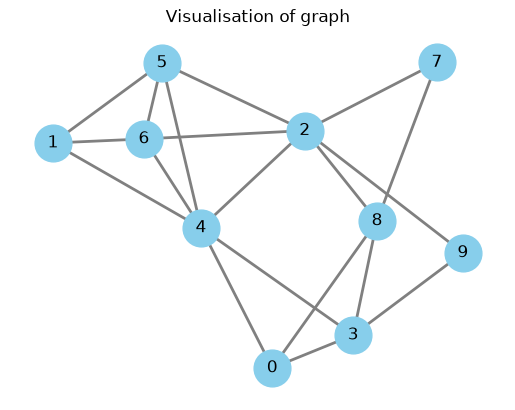

In [2]:
generate_erdos_graph(vertices=10, probability=0.5, seed=2, output=True)

In [3]:
def generate_constant_graph(vertices=6, degree=3, output=False, seed=67):
    import networkx as nx
    import matplotlib.pyplot as plt

    G = nx.random_regular_graph(d=degree, n=vertices, seed=seed)
    
    print("Is regular:", nx.is_regular(G))
    print("Node degrees:", dict(G.degree()))

    vertices = G.nodes()
    edges = G.edges()

    if output:
        print("Nodes:", vertices)
        print("Edges:", edges)
        print("Number of edges:", G.number_of_edges())
        
        pos = nx.spring_layout(G, seed=seed)
        nx.draw_networkx_nodes(G, pos, node_size=700, node_color="skyblue")
        nx.draw_networkx_edges(G, pos, width=2, edge_color="gray")
        nx.draw_networkx_labels(G, pos, font_size=12, font_family="sans-serif")
        
        plt.title("Visualisation of graph")
        plt.axis("off")
        plt.show()
    return G

Is regular: True
Node degrees: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3}
Nodes: [0, 1, 2, 3, 4, 5, 6, 7]
Edges: [(0, 1), (0, 7), (0, 3), (1, 2), (1, 4), (2, 4), (2, 6), (3, 4), (3, 5), (5, 7), (5, 6), (6, 7)]
Number of edges: 12


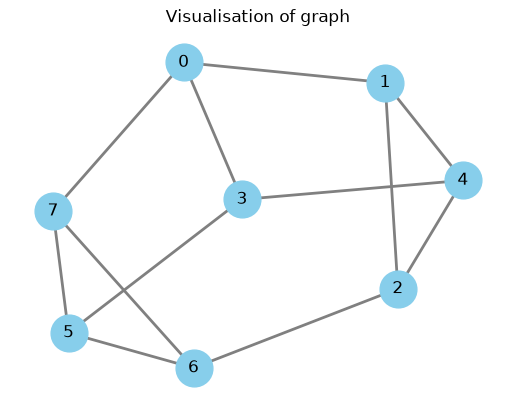

In [4]:
generate_constant_graph(8, 3, True, 110)

In [5]:
import networkx as nx
import matplotlib.pyplot as plt


def generate_cycle_with_chords(vertices=8, output=False, seed=67):
    import random
    import networkx as nx
    import matplotlib.pyplot as plt
    G = nx.cycle_graph(vertices)
    num_chords = vertices // 4
    candidates = [
        (u, v)
        for u in range(vertices)
        for v in range(u + 1, vertices)
        if not G.has_edge(u, v)
    ]
    rng = random.Random(seed)
    chords = rng.sample(candidates, num_chords)
    G.add_edges_from(chords)
    if output:
        pos = nx.spring_layout(G, seed=seed)
        nx.draw_networkx(
            G, pos, with_labels=True,
            node_color="skyblue", edge_color="gray"
        )
        nx.draw_networkx_edges(
            G, pos, edgelist=chords,
            edge_color="red", style="dashed", width=2
        )
        plt.title("Cycle with random chords")
        plt.axis("off")
        plt.show()
    return G

Is regular: False
Node degrees: {0: 3, 1: 2, 2: 3, 3: 2, 4: 3, 5: 2, 6: 3, 7: 2}
Nodes: [0, 1, 2, 3, 4, 5, 6, 7]
Edges: [(0, 1), (0, 7), (0, 4), (1, 2), (2, 3), (2, 6), (3, 4), (4, 5), (5, 6), (6, 7)]
Number of edges: 10


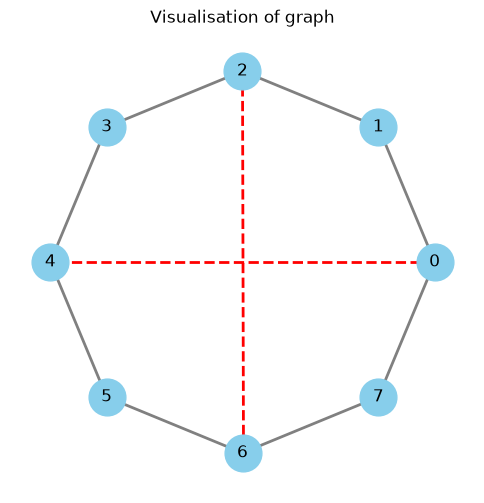

In [6]:
G = generate_cycle_with_chords(8, True)

## Greedy algorithm

In [7]:
def calculate_cut_value(G, partition):
    total = 0

    for u, v, data in G.edges(data=True):
        if partition[u] != partition[v]:
            total -= data.get("weight", 1.0)
        else:
            total += data.get("weight", 1.0)

    return total

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

def greedy_max_cut(G):
    print(len(G.edges()))
    partition = {}
    for vertex in G.nodes:
        a_neighbours = 0
        b_neighbours = 0
        
        for neighbor in G.neighbors(vertex):
            if neighbor in partition:
                weight = G[vertex][neighbor].get("weight", 1.0)
                if partition[neighbor] == 0:
                    a_neighbours += weight
                elif partition[neighbor] == 1:
                    b_neighbours += weight
        
        if a_neighbours > b_neighbours:
            partition[vertex] = 1
        elif b_neighbours > a_neighbours:
            partition[vertex] = 0
        else:
            count_A = sum(1 for v in partition if partition[v] == 0)
            count_B = sum(1 for v in partition if partition[v] == 1)
            partition[vertex] = 0 if count_A <= count_B else 1
            
    total_score = calculate_cut_value(G, partition)
    
    subset_A = [node for node, part in partition.items() if part == 0]
    subset_B = [node for node, part in partition.items() if part == 1]
    
    print(f"Set A: {subset_A}")
    print(f"Set B: {subset_B}")
    print("Score = ", total_score)
    
    node_colors = []
    for node in G.nodes:
        if partition[node] == 0:
            node_colors.append("skyblue")
        else:
            node_colors.append("tomato")
            
    pos = nx.spring_layout(G, seed=42)
    
    plt.figure(figsize=(6, 5))
    nx.draw(
        G, 
        pos, 
        with_labels=True, 
        node_color=node_colors, 
        node_size=800, 
        font_weight='bold', 
        edge_color='gray'
    )
    
    plt.title(f"Max-Cut \nScore : {total_score}")
    plt.show()
    
    return total_score, subset_A, subset_B

## Exact solver

In [11]:
def exact_max_cut(G):
    nodes = list(G.nodes())
    n = len(nodes)

    best_cut = -1
    best_partition = None

    # A partition and its complement have the same cut.
    # Fix the first node in group 0.
    for mask in range(1 << (n - 1)):
        partition = {nodes[0]: 0}

        for i in range(1, n):
            partition[nodes[i]] = (mask >> (i - 1)) & 1

        cut = sum(
            G[u][v].get("weight", 1)
            for u, v in G.edges()
            if partition[u] != partition[v]
        )

        if cut > best_cut:
            best_cut = cut
            best_partition = partition

    return best_cut, best_partition


def actual_cut_size(G, partition):
    return sum(
        G[u][v].get("weight", 1)
        for u, v in G.edges()
        if partition[u] != partition[v]
    )

## QAOA

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from scipy.optimize import minimize


def solve_max_cut_qaoa(
    G, p=1, shots=2048, seed=0, max_iterations=100
):
    import numpy as np
    from qiskit import QuantumCircuit
    from qiskit_aer import AerSimulator
    from scipy.optimize import minimize

    nodes = list(G.nodes())
    index = {node: i for i, node in enumerate(nodes)}

    edges = [
        (index[u], index[v], G[u][v].get("weight", 1))
        for u, v in G.edges()
    ]

    rng = np.random.default_rng(seed)
    backend = AerSimulator()
    evaluations = 0

    def run_circuit(params):
        gammas = params[:p]
        betas = params[p:]

        qc = QuantumCircuit(len(nodes), len(nodes))
        qc.h(range(len(nodes)))

        for gamma, beta in zip(gammas, betas):
            for u, v, weight in edges:
                qc.rzz(2 * gamma * weight, u, v)

            for q in range(len(nodes)):
                qc.rx(2 * beta, q)

        qc.measure(range(len(nodes)), range(len(nodes)))

        simulator_seed = int(rng.integers(0, 2**32 - 1))
        return backend.run(
            qc,
            shots=shots,
            seed_simulator=simulator_seed
        ).result().get_counts()

    def cut_from_bits(bits):
        # Qiskit displays the highest-index classical bit
        # on the left. Reverse to match the circuit qubits.
        ordered = bits[::-1]

        return sum(
            weight
            for u, v, weight in edges
            if ordered[u] != ordered[v]
        )

    def signed_score(bits):
        # Preserve your original minimization convention:
        # cut edges contribute -weight, uncut edges +weight.
        ordered = bits[::-1]

        return sum(
            -weight if ordered[u] != ordered[v] else weight
            for u, v, weight in edges
        )

    def objective(params):
        nonlocal evaluations
        evaluations += 1

        counts = run_circuit(params)
        total_shots = sum(counts.values())

        return sum(
            signed_score(bits) * count
            for bits, count in counts.items()
        ) / total_shots

    initial = rng.uniform(0, 2 * np.pi, 2 * p)

    result = minimize(
        objective,
        initial,
        method="COBYLA",
        options={"maxiter": max_iterations}
    )

    # Take a final sample using the optimized parameters.
    counts = run_circuit(result.x)
    total_shots = sum(counts.values())

    best_bits = max(counts, key=cut_from_bits)
    best_ordered = best_bits[::-1]

    partition = {
        nodes[i]: int(best_ordered[i])
        for i in range(len(nodes))
    }

    best_cut = cut_from_bits(best_bits)

    expected_cut = sum(
        cut_from_bits(bits) * count
        for bits, count in counts.items()
    ) / total_shots

    return {
        "partition": partition,
        "best_cut": best_cut,
        "expected_cut": expected_cut,
        "evaluations": evaluations,
        "optimizer_success": bool(result.success),
        "optimizer_message": str(result.message),
    }


## Experiment (example run)

In [15]:
graph = generate_constant_graph(16, 3, output=False, seed=1259)
solve_max_cut_qaoa(graph, p=2, shots=2048)

Is regular: True
Node degrees: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3, 8: 3, 9: 3, 10: 3, 11: 3, 12: 3, 13: 3, 14: 3, 15: 3}


{'partition': {0: 1,
  1: 1,
  2: 1,
  3: 1,
  4: 0,
  5: 1,
  6: 0,
  7: 0,
  8: 0,
  9: 0,
  10: 1,
  11: 0,
  12: 1,
  13: 0,
  14: 0,
  15: 0},
 'best_cut': 21,
 'expected_cut': 16.21630859375,
 'evaluations': 42,
 'optimizer_success': True,
 'optimizer_message': 'Return from COBYLA because the trust region radius reaches its lower bound.'}